# Lab 11 — Image and Video Processing
**ARTI 303 — Programming for AI**

**Name:** _[Rana Almaimany]_  **Student ID:** _[2250000431]_  **Section:** _[AI 02]_

---

### Warm-up: train a model in your browser (about 5 minutes, optional)

Before any code, build an image classifier with no code at all.

1. Open **[Teachable Machine](https://teachablemachine.withgoogle.com/)** in a desktop browser. Click **Get started**, then **Image Project** (if it asks which kind, choose the standard image model).
2. Rename the two classes after two **objects** (for example a pen and a mug). Please use objects, not faces: the tool can use your webcam, so keep people out of the frame.
3. For each class, click **Webcam** and hold the button to record about 20 samples, moving the object around a little. No webcam? Use **Upload** and add images from your computer instead.
4. Click **Train Model**. Then show the objects to the camera and watch the predictions.

> Training happens in your browser, and your samples stay on your
> computer unless you choose to save the project to Google Drive. Don't
> save it.

**Now try to break it.** Hold an object much closer or further away. Turn
it upside down. Dim the light, or change the background. Where does the
model fail?

Discuss with the person next to you (one minute):

- **Why did it fail?** The model only knows what it saw while training.
- **What did the website do that you couldn't see?** Before training, it
  had to turn every webcam frame into numbers of the same size and scale.
  Today's lab is that hidden step, done by hand. (And a webcam is a video,
  so the website was processing a stream of frames.)

---

### What this lab is really about

A folder of images arrives from five different places: different sizes,
different colour formats, some too dark, some grainy. Your model needs
exactly one thing: **every input is a 3 × 224 × 224 block of numbers on the
same scale.**

Between the folder and the model there are half a dozen ways to go wrong,
and **none of them raises an error**. This lab builds the safe route, step by
step, and then points it at a **video**.

| Part | The job | What you'll do |
|---|---|---|
| 1 | Audit the folder | find out what is really in your data |
| 2 | One size, one colour order | make every image the same shape, safely |
| 3 | Light and noise | repair a dark picture and a grainy one |
| 4 | Moving pixels | transformations, then augmentation for variety |
| 5 | Model-ready, and checked | normalise, build a tensor, validate, then *look* |
| 6 | Video | the same ideas, one frame at a time, plus motion |

After Part 6 there is a short AI checkpoint and a list of resources.

---

## Setup

> **Install OpenCV before the lab starts.** On Colab and Kaggle it is
> already installed. Torchvision (Lab 8) brings Pillow, and scikit-learn
> and Matplotlib came from earlier labs.

Same course folder, same environment as before:

```
arti303_lab/
├── .venv/
├── requirements.txt
├── lab01.ipynb ... lab10.ipynb
├── lab11.ipynb        <- this lab
├── data/
└── ...
```

**1.** Open `arti303_lab` in VS Code (`File → Open Folder`) — the folder
itself, not a lab file inside it.

**2.** Get the environment ready, in this order:

- Look for a `.venv` folder in the file list. If it isn't there, create
  it once: `python -m venv .venv`
- Activate it:

```bash
source .venv/bin/activate          # macOS / Linux / Git Bash
.venv\Scripts\Activate.ps1         # Windows PowerShell
```

- Check your prompt starts with `(.venv)`. If it shows `(base)`, you're
  in Anaconda's environment and packages will install to the wrong place.

**3.** Install OpenCV and record it:

```bash
python -m pip install opencv-python
python -m pip freeze > requirements.txt
```

**4.** Point this notebook at the same environment:
`Cmd+Shift+P` (macOS) / `Ctrl+Shift+P` (Windows) → **Python: Select
Interpreter** → the entry showing `.venv`. Then restart the kernel.

### Check your setup

In [2]:
import os
import sys

problems = []

if "google.colab" in sys.modules or os.path.exists("/kaggle"):
    print("[ok]   Running on Colab or Kaggle (no virtual environment needed)")
elif sys.prefix != sys.base_prefix:
    print("[ok]   Running inside a virtual environment")
else:
    print("[!]    NOT in a virtual environment")
    problems.append("Select the .venv interpreter, then restart the kernel")
print("       using:", sys.executable)
print()

for import_name, pip_name in [("numpy", "numpy"), ("cv2", "opencv-python"), ("PIL", "Pillow"),
                              ("torch", "torch"), ("torchvision", "torchvision"),
                              ("sklearn", "scikit-learn"), ("matplotlib", "matplotlib")]:
    try:
        module = __import__(import_name)
        print(f"[ok]   {pip_name} {module.__version__}")
    except ImportError:
        print(f"[!]    {pip_name} is not installed in this environment")
        problems.append(f"Run: python -m pip install {pip_name}")

if os.path.exists("requirements.txt"):
    names = [l.split("==")[0].strip().lower() for l in open("requirements.txt").read().splitlines() if l.strip()]
    if any(n.startswith("opencv-python") for n in names):
        print("[ok]   opencv-python is recorded in requirements.txt")
    else:
        print("[!]    opencv-python is missing from requirements.txt")
        problems.append("Run: python -m pip freeze > requirements.txt")
    if len(names) > 100:
        print("[!]    requirements.txt has", len(names), "packages - that looks like Anaconda's base")
        problems.append("Delete it, activate .venv, freeze again")

print()
print("Fix these first:" if problems else "Setup looks good.")
for item in problems:
    print("  -", item)

[ok]   Running inside a virtual environment
       using: /Users/ranakhaled/Documents/GitHub/arti303-2250000431-almaimany/.venv/bin/python

[ok]   numpy 2.5.3
[ok]   opencv-python 5.0.0
[ok]   Pillow 13.0.0
[ok]   torch 2.15.0
[ok]   torchvision 0.29.2
[ok]   scikit-learn 1.9.1
[ok]   matplotlib 3.11.2
[ok]   opencv-python is recorded in requirements.txt

Setup looks good.


---
### The messy folder

Two real photographs ship with scikit-learn. The cell below uses them to
build a folder that behaves like a real, untidy dataset: six files with
**different sizes, formats and problems**. It also defines `show`, a small
helper that draws images in a grid (you don't need to read it). `show`
expects **RGB** colours.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import cv2
from PIL import Image
from sklearn.datasets import load_sample_images

folder = "data/messy"
os.makedirs(folder, exist_ok=True)

photos = load_sample_images()
tower, flower = photos.images[0], photos.images[1]
rng = np.random.default_rng(11)

Image.fromarray(tower).save(f"{folder}/tower.png")
Image.fromarray(flower).convert("L").save(f"{folder}/flower_gray.png")                    # a grayscale file
Image.fromarray(flower).resize((96, 64)).save(f"{folder}/flower_thumb.jpg", quality=85)    # a tiny thumbnail
Image.fromarray((tower * 0.25).astype(np.uint8)).save(f"{folder}/tower_dark.png")          # underexposed
Image.fromarray(tower[:, 160:480]).save(f"{folder}/tower_tall.png")                        # a portrait crop
noisy = np.clip(flower.astype(float) + rng.normal(0, 25, flower.shape), 0, 255).astype(np.uint8)
Image.fromarray(noisy).save(f"{folder}/flower_noisy.png")                                   # grainy

names = sorted(os.listdir(folder))
print("files in the folder:", names)


def show(images, titles=None, cols=3, size=3.2):
    """Draw images in a grid. Works with arrays, PIL images and tensors (RGB colours)."""
    rows = -(-len(images) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for i, img in enumerate(images):
        if isinstance(img, torch.Tensor):
            img = img.detach().cpu()
            img = img.permute(1, 2, 0).numpy() if img.ndim == 3 else img.numpy()
        arr = np.asarray(img)
        if arr.ndim == 3 and arr.shape[-1] == 1:
            arr = arr[..., 0]
        if arr.dtype != np.uint8 and arr.min() < 0:
            arr = (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)   # stretch to 0-1, for display only
        axes[i].imshow(arr, cmap="gray" if arr.ndim == 2 else None)
        if titles:
            axes[i].set_title(titles[i], fontsize=10)
    fig.tight_layout()

files in the folder: ['flower_gray.png', 'flower_noisy.png', 'flower_thumb.jpg', 'tower.png', 'tower_dark.png', 'tower_tall.png']


---
# Part 1 · Audit the folder

To a computer, an image is an **array of numbers**: a grid of pixels, each
pixel a number (grayscale) or three numbers (colour). The attributes you
already check for every array tell you what you have:

| | Meaning |
|---|---|
| `shape` | `(height, width)` for grayscale, `(height, width, 3)` for colour |
| `dtype` | usually `uint8`: whole numbers from 0 (black) to 255 (white) |

Because an image is an array, a **crop is just a slice** (and, as in Lab 4, a
slice is a view of the same memory).

Before you write any pipeline, **look at what you actually have**. Read
each file exactly as it is stored: `cv2.IMREAD_UNCHANGED` means "don't
convert anything":

In [4]:
print(f"{'file':18} {'shape':16} {'dtype':7} {'brightness':>10}")
for name in names:
    img = cv2.imread(f"{folder}/{name}", cv2.IMREAD_UNCHANGED)
    print(f"{name:18} {str(img.shape):16} {str(img.dtype):7} {img.mean():>10.1f}")

file               shape            dtype   brightness
flower_gray.png    (427, 640)       uint8         66.1
flower_noisy.png   (427, 640, 3)    uint8         64.0
flower_thumb.jpg   (64, 96, 3)      uint8         62.0
tower.png          (427, 640, 3)    uint8        143.7
tower_dark.png     (427, 640, 3)    uint8         35.5
tower_tall.png     (427, 320, 3)    uint8        146.2


Already the folder is a mess:

- one file has **no channel dimension** at all (`flower_gray.png`)
- sizes range from a few thousand pixels to a quarter of a million
- one picture is **far darker** than the rest (its average brightness is
  much lower)

Here is another surprise. `cv2.imread` **converts by default**: it always
returns 3 channels, even for a grayscale file:

In [5]:
gray_path = f"{folder}/flower_gray.png"

print("default imread:   ", cv2.imread(gray_path).shape)
print("IMREAD_UNCHANGED: ", cv2.imread(gray_path, cv2.IMREAD_UNCHANGED).shape)
print("Pillow says the mode is:", Image.open(gray_path).mode, "  (L means grayscale)")

default imread:    (427, 640, 3)
IMREAD_UNCHANGED:  (427, 640)
Pillow says the mode is: L   (L means grayscale)


Convenient, but the information that this was grayscale is now **gone**.

### Exercise 1.1
Audit the folder in code. Using `folder` and `names` from above:

- `shapes`: a dictionary mapping each file name to its array shape (read
  with `cv2.IMREAD_UNCHANGED`)
- `gray_files`: the list of names whose array has only **2 dimensions**
- `smallest_file`: the name of the file with the fewest pixels (height × width)
- `darkest_file`: the name of the file with the lowest average pixel value

In [6]:

shapes = {}
gray_files = []
pixels = {}
brightness = {}

for name in names:
    img = cv2.imread(f"{folder}/{name}", cv2.IMREAD_UNCHANGED)
    shapes[name] = img.shape

    if img.ndim == 2:
        gray_files.append(name)

    pixels[name] = img.shape[0] * img.shape[1]
    brightness[name] = img.mean()

smallest_file = min(pixels, key=pixels.get)
darkest_file = min(brightness, key=brightness.get)


In [7]:
assert shapes is not None and gray_files is not None and smallest_file is not None and darkest_file is not None, "fill in all four"
assert set(shapes) == set(names), "shapes should have one entry for every file in the folder"
assert shapes["flower_gray.png"] == (427, 640), f"flower_gray.png should read as (427, 640): read it with cv2.IMREAD_UNCHANGED, you have {shapes['flower_gray.png']}"
assert gray_files == ["flower_gray.png"], f"only one file is grayscale (a 2-dimensional array), you have {gray_files}"
assert smallest_file == "flower_thumb.jpg", f"the smallest picture is the thumbnail, you have {smallest_file}"
assert darkest_file == "tower_dark.png", f"the darkest picture is tower_dark.png, you have {darkest_file}"
print("Exercise 1.1 correct.")

Exercise 1.1 correct.


### A problem the audit can't show: colour order

Shapes reveal size and channel problems. They can't reveal this one.
Pillow, Matplotlib, Torchvision and pretrained models all use **red, green,
blue**. **OpenCV** loads the very same file as **blue, green, red**:

same pixel, Pillow: [123  47  11] | OpenCV: [ 11  47 123]
OpenCV is Pillow with the channels reversed: True


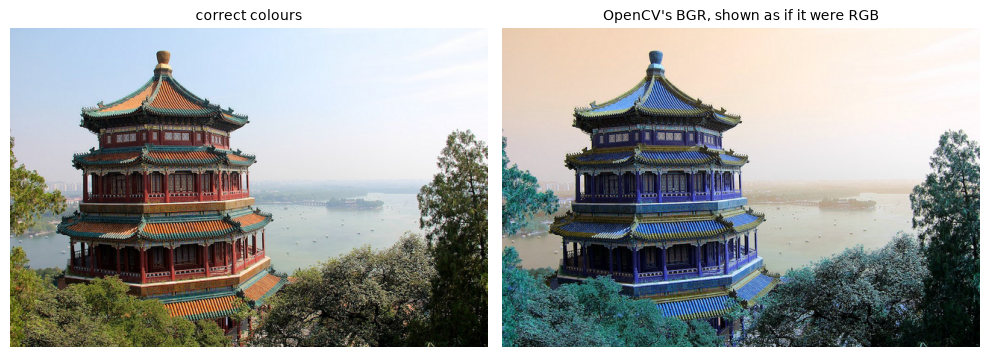

In [8]:
tower_path = f"{folder}/tower.png"

rgb_pillow = np.array(Image.open(tower_path))
bgr = cv2.imread(tower_path)

print("same pixel, Pillow:", rgb_pillow[100, 200], "| OpenCV:", bgr[100, 200])
print("OpenCV is Pillow with the channels reversed:", np.array_equal(bgr[..., ::-1], rgb_pillow))

show([rgb_pillow, bgr], ["correct colours", "OpenCV's BGR, shown as if it were RGB"], cols=2, size=5)

Nothing crashed. The right-hand picture is simply wrong (a blue roof under
an orange sky), and a model trained on it would learn the wrong colours without a
single warning.

> **The rule:** OpenCV is **BGR**. Convert with
> `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` as soon as you load a colour image.

---
# Part 2 · One size, one colour order

A model expects **every input identical**: here `224 × 224`, 3 colour
channels, RGB. Your folder has six different sizes and a mix of colour and
grayscale. Three fixes:

1. **Colour:** convert BGR to RGB (and let a grayscale image become 3
   identical channels).
2. **Shape:** cut a **square** from the middle of the picture.
3. **Size:** resize it to 224 × 224.

Step 2 matters. Our tower photo is wider than it is tall, so resizing it
**straight** to a square stretches it. Cropping a square first keeps its
proportions. And watch the argument order: `cv2.resize` takes
**(width, height)**, while `.shape` reports **(height, width)**:

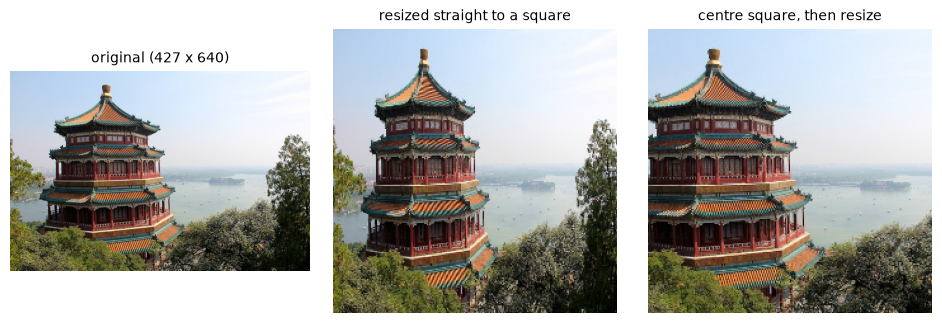

In [9]:
img = cv2.cvtColor(cv2.imread(tower_path), cv2.COLOR_BGR2RGB)

squashed = cv2.resize(img, (224, 224))

side = min(img.shape[:2])
top = (img.shape[0] - side) // 2
left = (img.shape[1] - side) // 2
cropped = cv2.resize(img[top:top + side, left:left + side], (224, 224))

show([img, squashed, cropped], ["original (427 x 640)", "resized straight to a square", "centre square, then resize"])

### Exercise 2.1
Write `standardise(path, size=224)`. For **any** image file it must return
a `(size, size, 3)` `uint8` array in **RGB**, using the centre-square
approach. (Hint: the default `cv2.imread` already gives 3 channels, even
for a grayscale file.)

In [10]:

def standardise(path, size=224):
    """Return a centre-cropped RGB uint8 image."""
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h, w = img.shape[:2]
    side = min(h, w)

    top = (h - side) // 2
    left = (w - side) // 2

    cropped = img[top:top + side, left:left + side]
    resized = cv2.resize(cropped, (size, size))

    return resized



In [11]:
outputs = {name: standardise(f"{folder}/{name}") for name in names}

for name, out in outputs.items():
    assert out is not None, "standardise returned None"
    assert out.shape == (224, 224, 3) and out.dtype == np.uint8, f"{name}: expected (224, 224, 3) uint8, got {out.shape} {out.dtype}"

# The grayscale file must become three identical channels
g = outputs["flower_gray.png"]
assert np.array_equal(g[..., 0], g[..., 1]) and np.array_equal(g[..., 1], g[..., 2]), "a grayscale file should become 3 identical channels"

# Compare the tower with the right answer, at a coarse scale so different resize methods are judged fairly
rgb_ref = np.array(Image.open(tower_path))
s = min(rgb_ref.shape[:2])
t, l = (rgb_ref.shape[0] - s) // 2, (rgb_ref.shape[1] - s) // 2
centre_ref = cv2.resize(rgb_ref[t:t + s, l:l + s], (224, 224))
squashed_ref = cv2.resize(rgb_ref, (224, 224))
coarse = lambda a: cv2.resize(a, (8, 8), interpolation=cv2.INTER_AREA).astype(float)
gap = lambda a, b: float(np.abs(coarse(a) - coarse(b)).mean())

tower_out = outputs["tower.png"]
assert gap(tower_out, centre_ref) < gap(tower_out, centre_ref[..., ::-1]), "the colours are in BGR order: convert with cv2.COLOR_BGR2RGB"
assert gap(tower_out, centre_ref) < gap(tower_out, squashed_ref), "the picture looks squashed: cut a square from the CENTRE first, then resize"
assert gap(tower_out, centre_ref) < 6, "the tower doesn't match the centre square of the photo: check the crop"
print("Exercise 2.1 correct.")

Exercise 2.1 correct.


Now all six files have the same shape. Look at them:

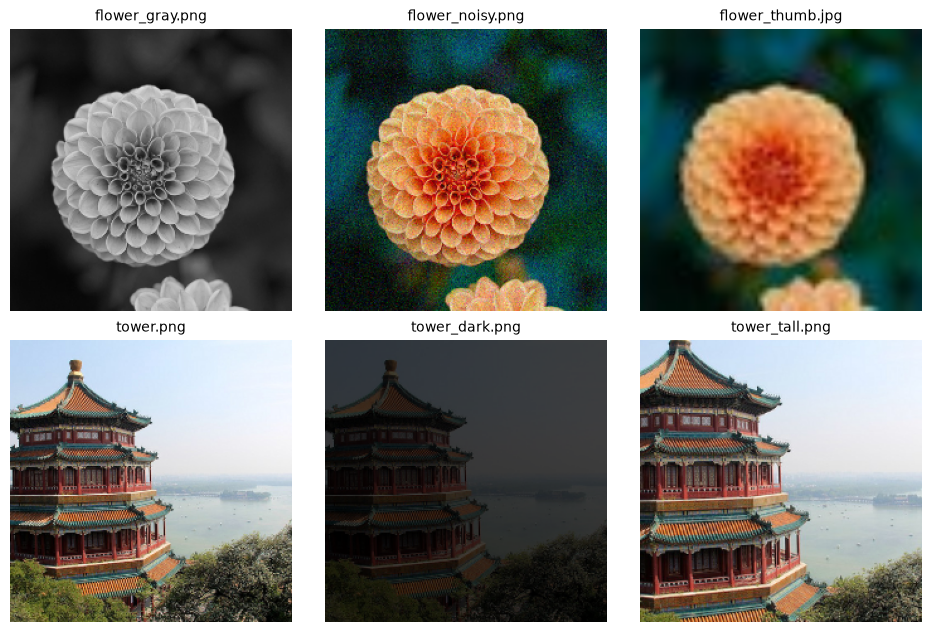

In [12]:
if any(out is None for out in outputs.values()):
    print("Finish Exercise 2.1 to see this.")
else:
    show([outputs[n] for n in names], names)

Same shape, but not the same **quality**: one is far too dark, and one is
grainy. That's Part 3.

---
# Part 3 · Light and noise

### Too dark

**Brightness** is the average pixel value: 0 is black, 255 is white. The
dark photo averages about 35, so a model trained on normally lit pictures
would barely see anything. A histogram shows how its pixel values pile up
near zero:

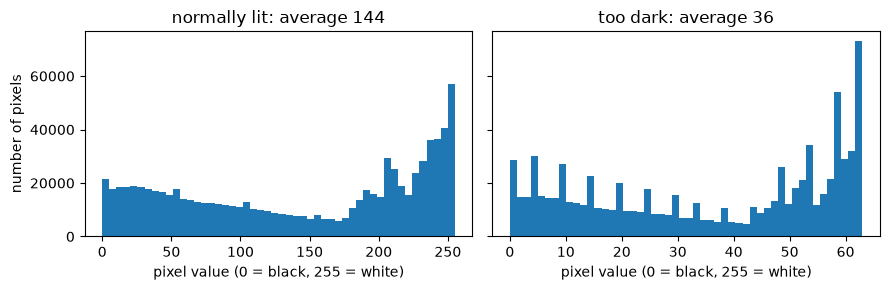

In [13]:
dark = cv2.cvtColor(cv2.imread(f"{folder}/tower_dark.png"), cv2.COLOR_BGR2RGB)
normal = cv2.cvtColor(cv2.imread(f"{folder}/tower.png"), cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, image, title in [(axes[0], normal, "normally lit"), (axes[1], dark, "too dark")]:
    ax.hist(image.ravel(), bins=50)
    ax.set_title(f"{title}: average {image.mean():.0f}")
    ax.set_xlabel("pixel value (0 = black, 255 = white)")
axes[0].set_ylabel("number of pixels")
fig.tight_layout()

Two fixes. **Multiplying** every pixel by a gain (`cv2.convertScaleAbs`)
is the simplest. **Histogram equalisation** (`cv2.equalizeHist`, on a
grayscale image) spreads the values across the whole range:

gain needed: x3.1


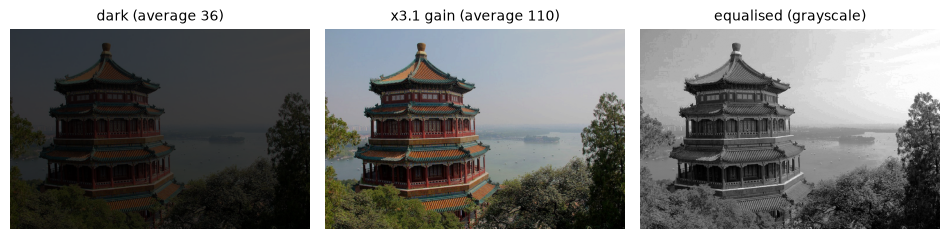

In [14]:
gain = 110 / dark.mean()
brightened = cv2.convertScaleAbs(dark, alpha=gain)
equalised = cv2.equalizeHist(cv2.cvtColor(dark, cv2.COLOR_RGB2GRAY))

print(f"gain needed: x{gain:.1f}")
show([dark, brightened, equalised], [f"dark (average {dark.mean():.0f})", f"x{gain:.1f} gain (average {brightened.mean():.0f})", "equalised (grayscale)"])

### Exercise 3.1
Write `brighten(img, dark_below=50, target=110)`:

- if the image's **average** pixel value is **at least** `dark_below`, return
  it **unchanged** (a copy is fine)
- otherwise multiply it by the gain that brings its average up to
  `target` (`cv2.convertScaleAbs(img, alpha=...)`)

Normal pictures must not be touched: a pipeline that "fixes" everything
damages good data.

In [15]:

def brighten(img, dark_below=50, target=110):
    """Brighten only the pictures that are too dark."""
    if img.mean() >= dark_below:
        return img

    gain = target / img.mean()
    return cv2.convertScaleAbs(img, alpha=gain)


In [16]:
dark_img = cv2.imread(f"{folder}/tower_dark.png")
fixed = brighten(dark_img)
assert fixed is not None, "brighten returned None"
assert fixed.shape == dark_img.shape and fixed.dtype == np.uint8, "the result should keep the same shape and uint8 dtype"
assert 100 <= fixed.mean() <= 120, f"the dark picture's average should rise to about 110, it is {fixed.mean():.1f}"

for ok_name in ["tower.png", "flower_gray.png", "flower_noisy.png", "tower_tall.png"]:
    ok_img = cv2.imread(f"{folder}/{ok_name}")
    assert np.array_equal(brighten(ok_img), ok_img), f"{ok_name} is not dark (average {ok_img.mean():.0f}): it must come back unchanged"
print("Exercise 3.1 correct.")

Exercise 3.1 correct.


### Too grainy

The noisy flower has random speckle on every pixel. **Blurring** replaces
each pixel with an average of its neighbours, which smooths the speckle
away. `cv2.GaussianBlur(img, (k, k), 0)` blurs with a `k × k` window (`k`
odd). Because we have the clean flower too, we can **measure** how far each
blur is from the truth:

window  1 x 1 : average error vs the clean photo = 17.10
window  3 x 3 : average error vs the clean photo =  8.20
window  5 x 5 : average error vs the clean photo =  7.20
window  9 x 9 : average error vs the clean photo =  6.69
window 15 x 15: average error vs the clean photo =  7.03
window 31 x 31: average error vs the clean photo =  8.69
window 61 x 61: average error vs the clean photo = 11.57

best window: 9 x 9


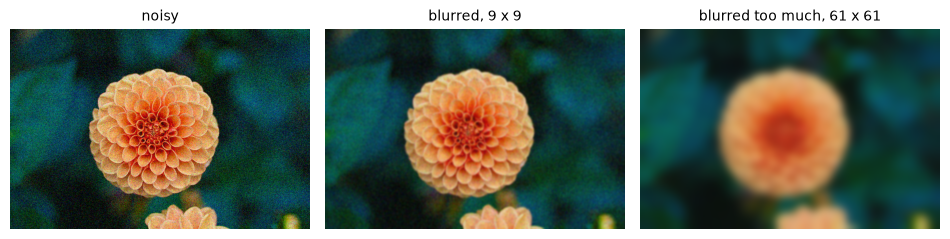

In [17]:
flower_clean = np.array(Image.fromarray(flower))
flower_noisy = cv2.cvtColor(cv2.imread(f"{folder}/flower_noisy.png"), cv2.COLOR_BGR2RGB)

sizes = [1, 3, 5, 9, 15, 31, 61]
errors = {}
for k in sizes:
    blurred = flower_noisy if k == 1 else cv2.GaussianBlur(flower_noisy, (k, k), 0)
    errors[k] = np.abs(blurred.astype(int) - flower_clean.astype(int)).mean()
    print(f"window {k:>2} x {k:<2}: average error vs the clean photo = {errors[k]:5.2f}")

best = min(errors, key=errors.get)
print(f"\nbest window: {best} x {best}")
show([flower_noisy, cv2.GaussianBlur(flower_noisy, (best, best), 0), cv2.GaussianBlur(flower_noisy, (61, 61), 0)],
     ["noisy", f"blurred, {best} x {best}", "blurred too much, 61 x 61"])

There is a **sweet spot**. Some blur removes noise, and too much blur
removes the **detail** along with it. Remember this the next time someone says
"just smooth it".

---
# Part 4 · Moving pixels: transformations, then augmentation

Back to the warm-up: your model broke when the object was closer, tilted
or upside down, because it had only seen it one way. To fix that you need
two things: a way to **move pixels around**, and a way to do it
**randomly**, on purpose.

### The transformation toolbox

Moving pixels is just arithmetic on coordinates. Every transformation
except cropping is a small **matrix** that says where each pixel goes. A
point `(x, y)` is written `(x, y, 1)`, and the extra `1` is what lets one
matrix both stretch **and** shift. (It is the matrix product from Lab 4.)

For example, **translation** by `(dx, dy)` uses `[[1, 0, dx], [0, 1, dy]]`.
Six transformations on one grayscale photo:

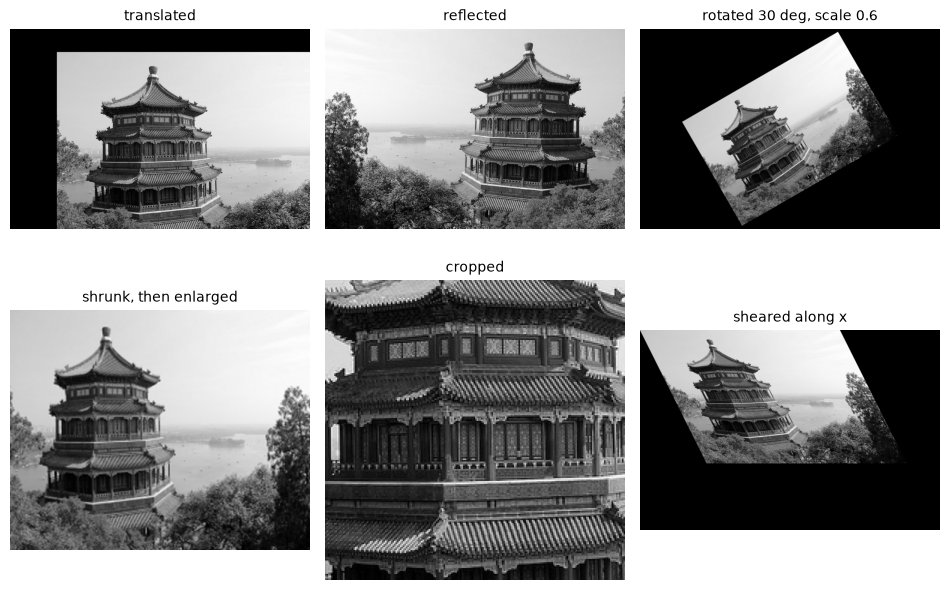

In [18]:
gray = cv2.imread(tower_path, cv2.IMREAD_GRAYSCALE)
rows, cols = gray.shape

M_translate = np.float32([[1, 0, 100], [0, 1, 50]])                  # 100 right, 50 down
translated = cv2.warpAffine(gray, M_translate, (cols, rows))

reflected = cv2.flip(gray, 1)                                         # left-right

M_rotate = cv2.getRotationMatrix2D((cols / 2, rows / 2), 30, 0.6)     # 30 degrees, shrink to 60%
rotated = cv2.warpAffine(gray, M_rotate, (cols, rows))

shrunk = cv2.resize(gray, (250, 200), interpolation=cv2.INTER_AREA)   # scaling
enlarged = cv2.resize(shrunk, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC)

cropped = gray[100:300, 100:300]                                      # cropping is just slicing

M_shear_x = np.float32([[1, 0.5, 0], [0, 1, 0], [0, 0, 1]])           # shear along x: slant the picture
sheared = cv2.warpPerspective(gray, M_shear_x, (int(cols * 1.5), int(rows * 1.5)))

show([translated, reflected, rotated, enlarged, cropped, sheared],
     ["translated", "reflected", "rotated 30 deg, scale 0.6", "shrunk, then enlarged", "cropped", "sheared along x"])

To see the matrix at work, find where the x-shear sends the point
`(0, 1)`:

In [19]:
point = np.array([0, 1, 1])
print("x-shear moves (0, 1) to:", (M_shear_x @ point)[:2], "  <- x changed by 0.5 * y")

x-shear moves (0, 1) to: [0.5 1. ]   <- x changed by 0.5 * y


### Exercise 4.1
Write `translate(img, dx, dy)`: shift an image `dx` pixels **right** and
`dy` pixels **down**, keeping its size (use `cv2.warpAffine` with a
translation matrix, as above). The space that opens up is filled with 0
(black).

In [20]:

def translate(img, dx, dy):
    """Shift img dx pixels right and dy pixels down, keeping its size."""
    rows, cols = img.shape[:2]
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    return cv2.warpAffine(img, M, (cols, rows))


In [21]:
test_img = np.random.default_rng(0).integers(1, 255, (6, 8)).astype(np.uint8)
moved_img = translate(test_img, 3, 2)

assert moved_img is not None, "translate returned None"
assert moved_img.shape == test_img.shape, "the shifted image should keep its size"
assert np.array_equal(moved_img[2:, 3:], test_img[:-2, :-3]), "the content should move 3 pixels right and 2 down"
assert not moved_img[:2].any() and not moved_img[:, :3].any(), "the space that opens up should be filled with 0"
print("Exercise 4.1 correct.")

Exercise 4.1 correct.


### Augmentation: the same moves, at random

**Augmentation** gives the model **random variations** of each training
image: a random flip, a small random rotation, a random brightness change.
It increases the diversity of your data **without collecting new data**.
It happens on the fly: every time an image is loaded, a fresh random
variation is made. Torchvision (Lab 8) provides random versions of everything
above, plus colour changes, blurring and **random erasing** (hiding a
random patch, so the model copes with partly hidden objects). Five random
variations of one photo:

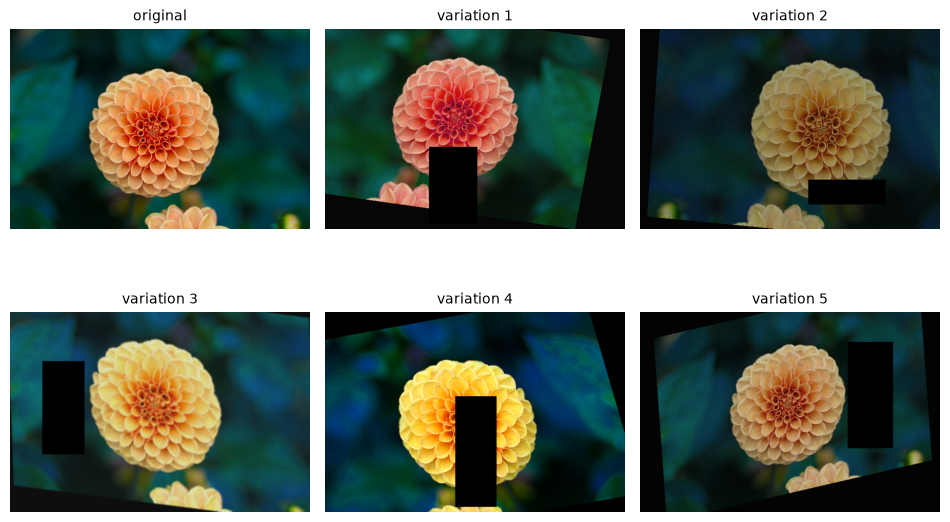

In [22]:
from torchvision import transforms

pil_flower = Image.fromarray(flower)

augment = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1), shear=10),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.05),
    transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5)),
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.7, scale=(0.02, 0.1)),
])

torch.manual_seed(0)
variants = [augment(pil_flower) for _ in range(5)]
show([pil_flower] + variants, ["original"] + [f"variation {i}" for i in range(1, 6)])

Two rules:

**1. Augmentation keeps the label true.** A flipped flower is still a
flower. A flipped digit `2` is not a `2`. Choose variations that can't
change what the picture *is*.

**2. Augment the training images only.** Test images get only the fixed
steps (resize, scale), the same ones every time. Augmenting the test set is
the image version of fitting on test data from Lab 7: your score would be
measured on altered, random pictures, and wouldn't mean anything.

### Exercise 4.2
Build two pipelines for photos like `pil_flower`:

- `train_tf`: a `Compose` of **at least two random transforms** (for
  example `RandomHorizontalFlip`, `RandomRotation`, `ColorJitter`),
  **ending with `ToTensor()`**
- `eval_tf`: `Resize((200, 200))` then `ToTensor()`, with **nothing random**

In [23]:

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor()
])

eval_tf = transforms.Compose([
    transforms.Resize((200, 200)),
    transforms.ToTensor()
])



In [24]:
assert train_tf is not None and eval_tf is not None, "fill in train_tf and eval_tf"

def is_random(name):
    return name.startswith("Random") or name == "ColorJitter"

train_names = [type(t).__name__ for t in train_tf.transforms]
eval_names = [type(t).__name__ for t in eval_tf.transforms]

assert sum(is_random(n) for n in train_names) >= 2, "train_tf needs at least two random transforms"
assert train_names[-1] == "ToTensor", "end train_tf with ToTensor()"
a, b = train_tf(pil_flower), train_tf(pil_flower)
assert a.dtype == torch.float32 and a.shape == b.shape, "train_tf should give float32 tensors of one shape"
assert not torch.equal(a, b), "two calls gave the SAME image: train_tf should be random"

assert not any(is_random(n) for n in eval_names), "eval_tf must not contain anything random"
assert tuple(eval_tf(pil_flower).shape) == (3, 200, 200), "eval_tf should give a (3, 200, 200) tensor"
assert torch.equal(eval_tf(pil_flower), eval_tf(pil_flower)), "eval_tf should give the same result every time"
print("Exercise 4.2 correct.")

Exercise 4.2 correct.


---
# Part 5 · Model-ready, and checked

You have the pieces. A complete image pipeline chains them:

> **same size and colour** (Part 2) → **repair light and noise** (Part 3) →
> **augment, training only** (Part 4) → **normalise and make a tensor** →
> model

The last step is new. Two things need to happen:

1. **Normalise.** Scale pixels from 0 to 255 into **0 to 1**, then
   **standardise** each colour channel: subtract its mean and divide by its
   standard deviation. It's the same idea as the scaling in Lab 7: values
   centred near 0 with a spread near 1. The numbers below (the average and
   spread of a large collection of photos) are the standard ones used with
   many pretrained models.
2. **Rearrange to a tensor.** Images are `height × width × channels`;
   PyTorch wants `channels × height × width`.

Parts 2 and 3 as tidy helpers (so this part doesn't depend on your
exercise answers):

In [25]:
def load_rgb_square(path, size=224):
    """Part 2 as a helper: any file -> (size, size, 3) uint8 RGB."""
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    side = min(img.shape[:2])
    top, left = (img.shape[0] - side) // 2, (img.shape[1] - side) // 2
    return cv2.resize(img[top:top + side, left:left + side], (size, size))


def brighten_if_dark(img, dark_below=50, target=110):
    """Part 3 as a helper."""
    average = img.mean()
    return img.copy() if average >= dark_below else cv2.convertScaleAbs(img, alpha=target / average)


MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)    # standard values for RGB photos
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

print("ready:", load_rgb_square(tower_path).shape)

ready: (224, 224, 3)


### Exercise 5.1
Write `to_tensor(img)`: it takes an **RGB `uint8`** image of shape
`(height, width, 3)` and returns a **`float32` tensor** of shape
`(3, height, width)`:

1. scale 0 to 255 into 0 to 1
2. standardise with `MEAN` and `STD`
3. rearrange to channels first

In [26]:

def to_tensor(img):
    """RGB uint8 (H, W, 3) -> float32 tensor (3, H, W)."""
    img = img.astype(np.float32) / 255.0
    img = (img - MEAN) / STD
    img = img.transpose(2, 0, 1)
    return torch.from_numpy(img.copy())



In [27]:
sample = load_rgb_square(tower_path)
out = to_tensor(sample)

assert out is not None, "to_tensor returned None"
assert isinstance(out, torch.Tensor), "return a torch tensor"
assert tuple(out.shape) == (3, 224, 224), f"expected shape (3, 224, 224) = (channels, height, width), got {tuple(out.shape)}"
assert out.dtype == torch.float32, f"expected float32, got {out.dtype}"

expected = torch.from_numpy((((sample.astype(np.float32) / 255.0) - MEAN) / STD).transpose(2, 0, 1).copy())
if not torch.allclose(out, expected, atol=1e-5):
    unscaled = torch.from_numpy(((sample.astype(np.float32) - MEAN) / STD).transpose(2, 0, 1).copy())
    assert not torch.allclose(out, unscaled, atol=1e-3), "the pixels were never divided by 255: scale to 0-1 first"
    assert False, "the values differ from the expected result: scale to 0-1, then subtract MEAN and divide by STD"
print("Exercise 5.1 correct.")

Exercise 5.1 correct.


Now run the **whole folder** through the pipeline (including the dark
picture's repair) and stack the results into a **batch**:

batch: (6, 3, 224, 224) torch.float32   (batch, channels, height, width)
value range: -2.12 to 2.64


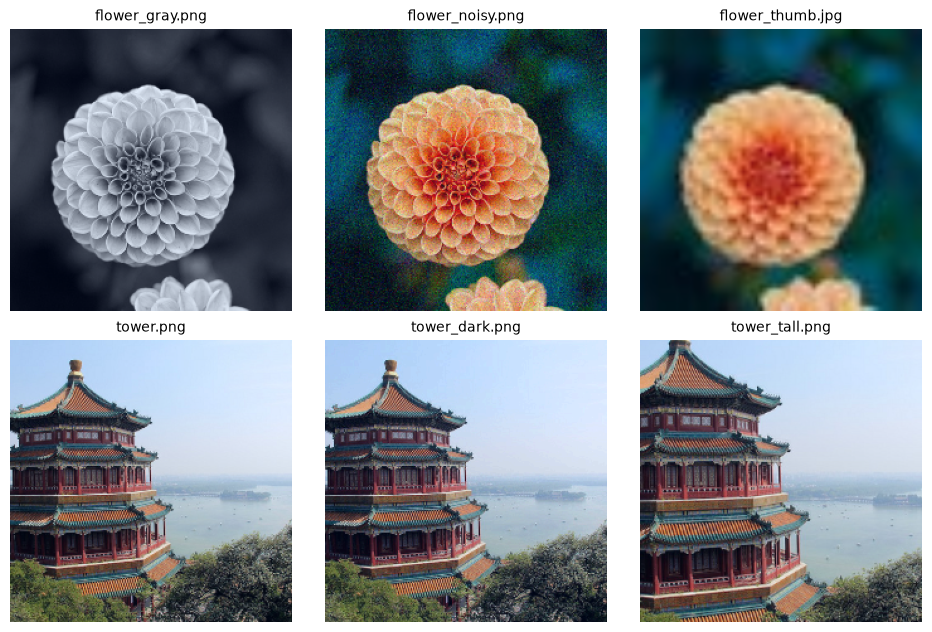

In [28]:
if to_tensor(sample) is None:
    batch = None
    print("Finish Exercise 5.1 to see this.")
else:
    batch = torch.stack([to_tensor(brighten_if_dark(load_rgb_square(f"{folder}/{n}"))) for n in names])
    print("batch:", tuple(batch.shape), batch.dtype, "  (batch, channels, height, width)")
    print("value range:", round(float(batch.min()), 2), "to", round(float(batch.max()), 2))
    show(list(batch), names)

### Validate the batch

Every mistake in this lab was silent, so the last tool is **checking**.
Five things to verify on every batch of images:

| Check | What it catches |
|---|---|
| 4 dimensions: (batch, channels, height, width) | a missing batch dimension, or a wrong layout |
| channels are 1 or 3 | height × width × channels order (the "channels" would be 224) |
| dtype is `float32` | raw `uint8` pixels |
| no NaN or infinite values | broken arithmetic |
| values in a sensible range | forgetting to scale 0 to 255 down |

### Exercise 5.2
Write `validate_images(batch)` for a tensor of images. It returns a **list
of problem descriptions** (strings), and an empty list if the batch looks
fine. Check for:

1. not exactly 4 dimensions, or a channel count that isn't 1 or 3
2. a dtype other than `float32`
3. any NaN or infinite value
4. values outside −3 to 3 (standardised photos live in roughly that range;
   raw 0 to 255 pixels do not)

In [29]:

def validate_images(batch):
    """Return a list of problems found."""
    problems = []

    if batch.ndim != 4:
        problems.append("Expected 4 dimensions")
    elif batch.shape[1] not in (1, 3):
        problems.append("Invalid number of channels")

    if batch.dtype != torch.float32:
        problems.append("Expected float32")

    if not torch.isfinite(batch).all():
        problems.append("NaN or infinite values found")

    if batch.numel() > 0:
        if (batch < -3).any() or (batch > 3).any():
            problems.append("Values outside -3 to 3")

    return problems



In [30]:
good = torch.rand(4, 3, 32, 32) * 2 - 1
assert validate_images(good) == [], "a clean (4, 3, 32, 32) float32 batch in -1..1 should give an empty list"
assert validate_images(torch.rand(4, 32, 32, 3)), "a height x width x channels batch should be reported"
assert validate_images(torch.rand(3, 32, 32)), "a batch with 3 dimensions should be reported"
assert validate_images(torch.randint(0, 255, (4, 3, 8, 8), dtype=torch.uint8)), "uint8 pixels should be reported"
assert validate_images(torch.rand(4, 3, 8, 8) * 255), "values up to 255 should be reported"
assert validate_images(torch.full((4, 3, 8, 8), float("nan"))), "NaN values should be reported"
print("Exercise 5.2 correct.")

if batch is None:
    print("your batch: finish Exercise 5.1 first")
else:
    print("your batch:", validate_images(batch) or "no problems found")

Exercise 5.2 correct.
your batch: no problems found


### The check no validator can do

Now the test that matters. Build the batch again, but with the bug from Part 1:
**skip the BGR → RGB conversion**. Then ask the validator:

validator on the BUGGY batch: no problems found



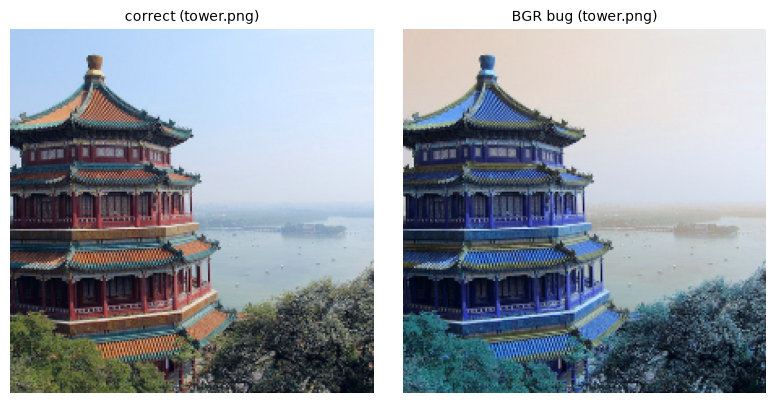

In [31]:
if batch is None:
    print("Finish Exercises 5.1 and 5.2 to see this.")
else:
    def load_bgr_square(path, size=224):
        img = cv2.imread(path)                      # no conversion: still BGR
        side = min(img.shape[:2])
        top, left = (img.shape[0] - side) // 2, (img.shape[1] - side) // 2
        return cv2.resize(img[top:top + side, left:left + side], (size, size))

    buggy_batch = torch.stack([to_tensor(brighten_if_dark(load_bgr_square(f"{folder}/{n}"))) for n in names])

    print("validator on the BUGGY batch:", validate_images(buggy_batch) or "no problems found")
    print()
    show([batch[3], buggy_batch[3]], ["correct (tower.png)", "BGR bug (tower.png)"], cols=2, size=4)

The validator says **"no problems found"**, and the right-hand picture is
wrong. The shape is right, the type is right, the range is right: only the
**colours** are wrong, and no check on numbers can see that.

> **Always look at an image.** A validator catches what it was written to
> catch. Your eyes catch the rest.

---
# Part 6 · Video: the same ideas, one frame at a time

A **video** is an **ordered sequence of images** (frames). A frame is just an
image, so **everything you have done in this lab works on a frame**.

To have something to work with, the next cell makes a short video: a ball
rolls across the picture, pauses, then rolls on. (Real videos work exactly
the same way.)

In [32]:
def make_video(path, n_frames=40, size=(240, 180), fps=10):
    """Write a short video: a ball moves, pauses, then moves again (you don't need to read this)."""
    width, height = size
    writer = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"MJPG"), fps, size)
    for i in range(n_frames):
        step = min(i, 14) if i <= 24 else i - 10            # frames 14 to 24 share one position
        x = 25 + 6 * step
        y = int(90 + 40 * np.sin(step / 3.0))
        frame = np.full((height, width, 3), (60, 40, 30), np.uint8)
        cv2.rectangle(frame, (0, height - 25), (width, height), (90, 110, 80), -1)
        cv2.putText(frame, "DEMO", (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1)
        cv2.circle(frame, (x, y), 14, (0, 140, 255), -1)
        writer.write(frame)
    writer.release()


os.makedirs("data/video", exist_ok=True)
video_path = "data/video/ball.avi"
make_video(video_path)

cap = cv2.VideoCapture(video_path)
print("video file:", video_path, "-", os.path.getsize(video_path) // 1024, "KB")
print("frames per second:", cap.get(cv2.CAP_PROP_FPS))
print("frame size:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), "x", int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))

ok, frame = cap.read()
print("first read ok:", ok, "| the frame is an array:", frame.shape, frame.dtype, "(BGR, like any OpenCV image)")
cap.release()

video file: data/video/ball.avi - 90 KB
frames per second: 10.0
frame size: 240 x 180
first read ok: True | the frame is an array: (180, 240, 3) uint8 (BGR, like any OpenCV image)


`cap.read()` hands over **one frame at a time**, together with an `ok`
flag that turns `False` when the video has ended. So processing a whole video
is a loop. Here is one that applies **any image function** to every frame
and writes a new video. We give it the edge detector `cv2.Canny`:

frames processed: 40


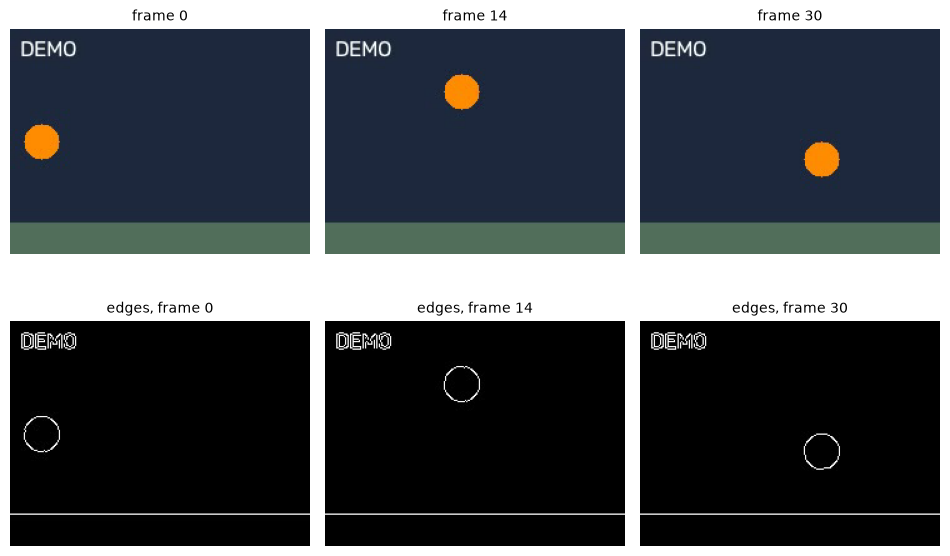

In [33]:
def process_video(in_path, out_path, func):
    """Apply func (frame in, frame out) to every frame of a video and save the result."""
    cap = cv2.VideoCapture(in_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    size = (int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
    writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"MJPG"), fps, size)
    count = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        writer.write(func(frame))
        count += 1
    cap.release()
    writer.release()
    return count


def edges_frame(frame):
    gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    return cv2.cvtColor(cv2.Canny(gray_frame, 80, 160), cv2.COLOR_GRAY2BGR)


n_done = process_video(video_path, "data/video/ball_edges.avi", edges_frame)
print("frames processed:", n_done)


def frame_at(path, index):
    cap = cv2.VideoCapture(path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, index)
    ok, frame = cap.read()
    cap.release()
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


picks = [0, 14, 30]
show([frame_at(video_path, i) for i in picks] + [frame_at("data/video/ball_edges.avi", i) for i in picks],
     [f"frame {i}" for i in picks] + [f"edges, frame {i}" for i in picks])

An image tool, run on every frame, with no new ideas.

What a video adds is **time**. Consecutive frames are strongly related, and
the **difference between two frames** shows what changed: that is
**motion**. `cv2.absdiff(a, b)` gives the per-pixel difference, and
counting the pixels that changed by more than a threshold turns it into a
number.

### Exercise 6.1
Write `motion_per_frame(path, threshold=25)`. Read the video frame by frame
(as grayscale, with a loop that stops when `ok` is `False`), and for **each
pair of consecutive frames** count how many pixels changed by **more than
`threshold`**. Return the counts as a list, so a video with `N` frames
gives `N - 1` numbers.

In [34]:

def motion_per_frame(path, threshold=25):
    """For each pair of consecutive frames, count changed pixels."""
    cap = cv2.VideoCapture(path)
    motion = []

    ok, prev = cap.read()
    if not ok:
        cap.release()
        return motion

    prev_gray = cv2.cvtColor(prev, cv2.COLOR_BGR2GRAY)

    while True:
        ok, frame = cap.read()
        if not ok:
            break

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        diff = cv2.absdiff(prev_gray, gray)
        count = int(np.sum(diff > threshold))
        motion.append(count)

        prev_gray = gray

    cap.release()
    return motion



In [35]:
motion = motion_per_frame(video_path)

assert motion is not None, "motion_per_frame returned None"
assert len(motion) == 39, f"40 frames give 39 pairs, you have {len(motion)}"
assert all(isinstance(m, int) for m in motion), "return plain integers (use int(...))"
assert all(m > 0 for m in motion[:14]), "the ball is moving at the start: those pairs should show motion"
assert all(m == 0 for m in motion[14:24]), "the ball pauses in the middle: those pairs should show no motion at all"
assert all(m > 0 for m in motion[24:]), "the ball moves again at the end"
print("Exercise 6.1 correct.")

Exercise 6.1 correct.


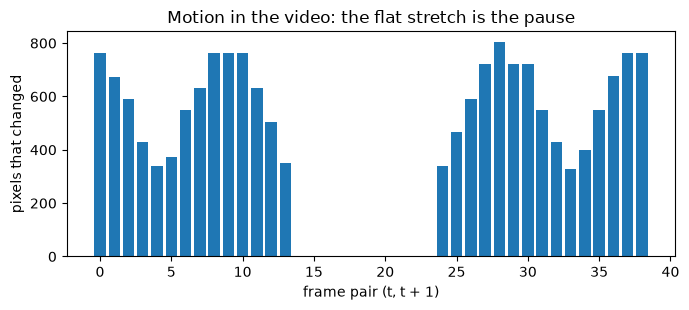

In [36]:
if motion is None:
    print("Finish Exercise 6.1 to see the motion chart.")
else:
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.bar(range(len(motion)), motion)
    ax.set_xlabel("frame pair (t, t + 1)")
    ax.set_ylabel("pixels that changed")
    ax.set_title("Motion in the video: the flat stretch is the pause")
    fig.tight_layout()

The flat stretch in the middle **is the pause**. You detected motion with
nothing but subtraction. That is the idea behind security cameras that
only record when something moves.

---
# AI checkpoint

**Pattern: the validator says yes. Now look.**

### Step 1
Give an AI assistant this exact prompt, unmodified:

> "Write a Python function `load_folder(folder)` using OpenCV and PyTorch
> that loads every image in a folder and returns one batch tensor for a
> neural network that expects 224x224 RGB images with values between 0 and 1."

### Step 2
Paste its function below and run it on `data/messy`. Then run **your
`validate_images`** on the result, and finally **draw the images** with
`show(list(ai_batch), names)`.

(6, 3, 224, 224) torch.float32
problems found: []


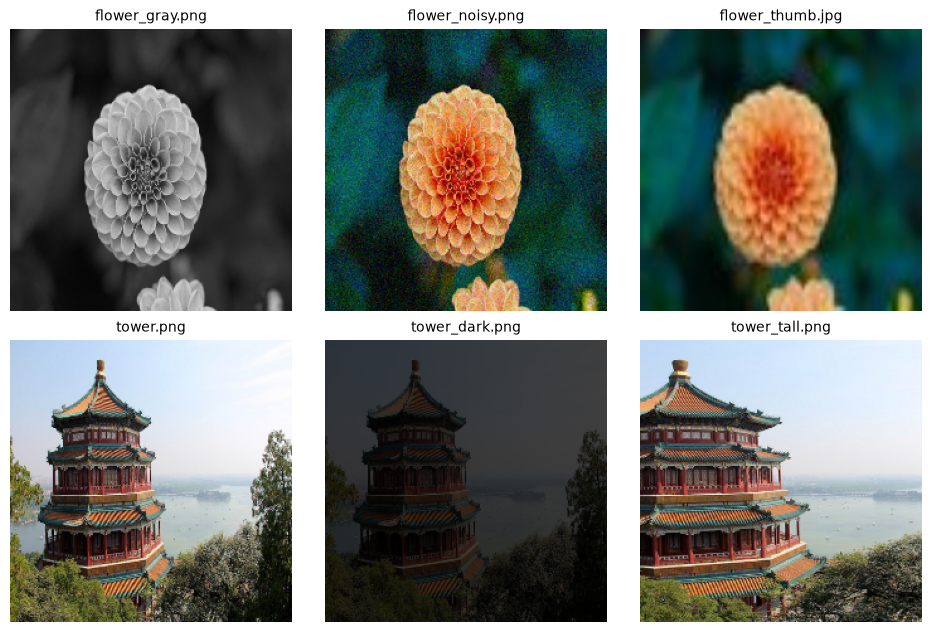

In [37]:
# Paste the AI assistant's function here, then run:
#
#   ai_batch = load_folder("data/messy")
#   print(tuple(ai_batch.shape), ai_batch.dtype)
#   print("problems found:", validate_images(ai_batch))
#   show(list(ai_batch), names)

def load_folder(folder):
    import os
    import cv2
    import torch
    import numpy as np

    images = []

    for name in sorted(os.listdir(folder)):
        path = os.path.join(folder, name)
        img = cv2.imread(path)

        if img is None:
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (224, 224))
        img = img.astype(np.float32) / 255.0
        img = torch.from_numpy(img).permute(2, 0, 1)

        images.append(img)

    return torch.stack(images)


ai_batch = load_folder("data/messy")

print(tuple(ai_batch.shape), ai_batch.dtype)
print("problems found:", validate_images(ai_batch))
show(list(ai_batch), names)



---
# Going further

Optional. Nothing here is required for the lab.

| Part | Resource | Why it's worth your time |
|---|---|---|
| 1 to 4, 6 | [OpenCV-Python tutorials](https://docs.opencv.org/4.x/d6/d00/tutorial_py_root.html) | Image basics, processing and video, with examples. |
| 4, 5 | [Torchvision transforms](https://docs.pytorch.org/vision/stable/transforms.html) | Every transform, including more augmentations. |
| All | [*Digital Image Processing* (PDF)](https://biomisa.org/uploads/2013/07/Digital.Image.Processing.Book.pdf) | A full textbook on the subject. |
| Warm-up | [Teachable Machine](https://teachablemachine.withgoogle.com/) | Retrain with objects that look alike, or add a third class, and see what breaks. |

### Optional: isolating an object

**Thresholding** turns a grayscale picture into black and white: pixels
above a cut-off become white. It is the simplest way to separate an object
from its background. It often leaves tiny white specks, which a
**morphological opening** (erode, then dilate) removes while keeping the
large shapes:

In [ ]:
mask = np.zeros((120, 120), np.uint8)
mask[30:90, 30:90] = 255                                  # one big white square

noise = np.random.default_rng(1).random((120, 120)) < 0.02
noisy_mask = mask.copy()
noisy_mask[noise & (mask == 0)] = 255                     # sprinkle white specks

opened = cv2.morphologyEx(noisy_mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))

print("white regions before:", cv2.connectedComponents(noisy_mask)[0] - 1)
print("white regions after: ", cv2.connectedComponents(opened)[0] - 1)
show([noisy_mask, opened], ["noisy mask", "after opening"], cols=2, size=3)

### Optional: a real dataset

Real image datasets plug into the same pipeline. Torchvision can download
**MNIST** (60,000 handwritten digits) in one line:

```python
from torchvision import datasets
mnist = datasets.MNIST(root="data", train=True, download=True)   # needs internet
```

It needs an internet connection and about 10 MB of space, and this
notebook doesn't run it. Try it yourself: `mnist[0]` returns a Pillow
image and a label, ready for the transforms from Part 4.

---
# Before you finish

- [ ] Every self-check cell prints "correct"
- [ ] `opencv-python` installed **and** recorded in `requirements.txt`
- [ ] AI checkpoint answered in your own words
- [ ] **Restart Kernel and Run All**: the whole notebook runs with no errors
- [ ] Committed and pushed